In [2]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import time
import os

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU kullanılabilir mi:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU kullanılacak.")


PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU kullanılabilir mi: True
GPU: Tesla T4


In [3]:
!pip -q install kagglehub


In [4]:
import kagglehub

dataset_path = kagglehub.dataset_download("moltean/fruits")

print("Veri seti indirildi!")
print("Konum:", dataset_path)


Using Colab cache for faster access to the 'fruits' dataset.
Veri seti indirildi!
Konum: /kaggle/input/fruits


In [5]:
import os

print("Ana klasör:", os.listdir(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    print("\nKlasör:", root)
    print("Alt klasörler:", dirs[:10])
    print("Dosya sayısı:", len(files))

    if root.count(os.sep) - dataset_path.count(os.sep) >= 2:
        dirs.clear()


Ana klasör: ['fruits-360_100x100', 'fruits-360_3-body-problem', 'fruits-360_meta', 'fruits-360_original-size', 'fruits-360_multi']

Klasör: /kaggle/input/fruits
Alt klasörler: ['fruits-360_100x100', 'fruits-360_3-body-problem', 'fruits-360_meta', 'fruits-360_original-size', 'fruits-360_multi']
Dosya sayısı: 0

Klasör: /kaggle/input/fruits/fruits-360_100x100
Alt klasörler: ['fruits-360']
Dosya sayısı: 0

Klasör: /kaggle/input/fruits/fruits-360_100x100/fruits-360
Alt klasörler: ['Training', 'Test']
Dosya sayısı: 2

Klasör: /kaggle/input/fruits/fruits-360_3-body-problem
Alt klasörler: ['fruits-360-3-body-problem']
Dosya sayısı: 0

Klasör: /kaggle/input/fruits/fruits-360_3-body-problem/fruits-360-3-body-problem
Alt klasörler: ['Training', 'Test']
Dosya sayısı: 2

Klasör: /kaggle/input/fruits/fruits-360_meta
Alt klasörler: ['fruits-360-meta']
Dosya sayısı: 0

Klasör: /kaggle/input/fruits/fruits-360_meta/fruits-360-meta
Alt klasörler: ['Meta', 'Papers']
Dosya sayısı: 3

Klasör: /kaggle/input

In [6]:
data_path = os.path.join(
    dataset_path,
    "fruits-360_original-size",
    "fruits-360-original-size"
)

for split in ["Training", "Validation", "Test"]:
    split_path = os.path.join(data_path, split)
    classes = sorted(os.listdir(split_path))

    print(f"\n{split} klasörü")
    print("Sınıf sayısı:", len(classes))
    print("İlk 20 sınıf:", classes[:20])



Training klasörü
Sınıf sayısı: 163
İlk 20 sınıf: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7', 'Apple 8', 'Apple 9', 'Apple Braeburn 1', 'Apple Red Yellow 2']

Validation klasörü
Sınıf sayısı: 163
İlk 20 sınıf: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7', 'Apple 8', 'Apple 9', 'Apple Red Yellow 2', 'Avocado Black 1']

Test klasörü
Sınıf sayısı: 163
İlk 20 sınıf: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7', 'Apple 8', 'Apple 9', 'Apple Braeburn 1', 'Apple Red Yellow 2']


In [7]:
selected_classes = [
    "Apple Braeburn 1",
    "Banana 1",
    "Orange 1",
    "Pear 1",
    "Strawberry 1"
]

for split in ["Training", "Validation", "Test"]:
    print(f"\n{split}:")

    for class_name in selected_classes:
        folder = os.path.join(data_path, split, class_name)

        if os.path.exists(folder):
            image_count = len(os.listdir(folder))
            print(f"{class_name}: {image_count} görsel")
        else:
            print(f"{class_name}: BULUNAMADI")



Training:
Apple Braeburn 1: 320 görsel
Banana 1: BULUNAMADI
Orange 1: BULUNAMADI
Pear 1: 326 görsel
Strawberry 1: BULUNAMADI

Validation:
Apple Braeburn 1: BULUNAMADI
Banana 1: BULUNAMADI
Orange 1: BULUNAMADI
Pear 1: 162 görsel
Strawberry 1: BULUNAMADI

Test:
Apple Braeburn 1: 160 görsel
Banana 1: BULUNAMADI
Orange 1: BULUNAMADI
Pear 1: 162 görsel
Strawberry 1: BULUNAMADI


In [8]:
for split in ["Training", "Validation", "Test"]:
    classes = sorted(os.listdir(os.path.join(data_path, split)))

    print(f"\n--- {split} ---")

    for fruit in ["Apple", "Banana", "Orange", "Pear", "Strawberry"]:
        matches = [c for c in classes if c.startswith(fruit)]
        print(f"\n{fruit}:")
        print(matches[:15])



--- Training ---

Apple:
['Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7']

Banana:
['Banana 2', 'Banana 3', 'Banana 4']

Orange:
['Orange 2', 'Orange 3', 'Orange 4', 'Orange 5', 'Orange peeled 1']

Pear:
['Pear 1', 'Pear 10', 'Pear 11', 'Pear 12', 'Pear 13', 'Pear 3', 'Pear 5', 'Pear 6', 'Pear 7', 'Pear 8', 'Pear 9', 'Pear common 1']

Strawberry:
['Strawberry 2', 'Strawberry 3']

--- Validation ---

Apple:
['Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7']

Banana:
['Banana 2', 'Banana 3', 'Banana 4']

Orange:
['Orange 2', 'Orange 3', 'Orange 4', 'Orange 5', 'Orange peeled 1']

Pear:
['Pear 1', 'Pear 10', 'Pear 11', 'Pear 12', 'Pear 13', 'Pear 3', 'Pear 5', 'Pear 6', 'Pear 7', 'Pear 8', 'Pear 9', 'Pear common 1']

Strawberry:
['Straw

In [9]:
selected_classes = [
    "Apple 10",
    "Banana 2",
    "Orange 2",
    "Pear 1",
    "Strawberry 2"
]

class_names = ["Elma", "Muz", "Portakal", "Armut", "Çilek"]

for split in ["Training", "Validation", "Test"]:
    print(f"\n{split}")

    for name in selected_classes:
        folder = os.path.join(data_path, split, name)
        count = len(os.listdir(folder))
        print(f"{name}: {count} görsel")



Training
Apple 10: 465 görsel
Banana 2: 149 görsel
Orange 2: 468 görsel
Pear 1: 326 görsel
Strawberry 2: 178 görsel

Validation
Apple 10: 234 görsel
Banana 2: 75 görsel
Orange 2: 234 görsel
Pear 1: 162 görsel
Strawberry 2: 89 görsel

Test
Apple 10: 231 görsel
Banana 2: 74 görsel
Orange 2: 231 görsel
Pear 1: 162 görsel
Strawberry 2: 88 görsel


In [10]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import glob
import random

class FruitDataset(Dataset):
    def __init__(self, split, transform=None):
        self.samples = []
        self.transform = transform

        for label, folder in enumerate(selected_classes):
            folder_path = os.path.join(data_path, split, folder)

            for file in glob.glob(os.path.join(folder_path, "*")):
                if file.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append((file, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


train_raw = FruitDataset("Training")
val_raw = FruitDataset("Validation")
test_raw = FruitDataset("Test")

print("Eğitim görseli:", len(train_raw))
print("Doğrulama görseli:", len(val_raw))
print("Test görseli:", len(test_raw))


Eğitim görseli: 1586
Doğrulama görseli: 794
Test görseli: 786


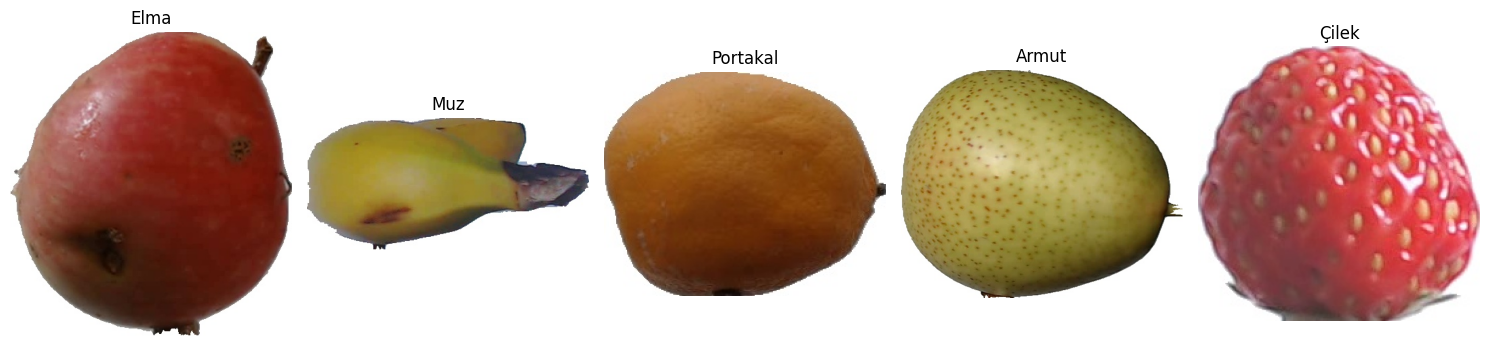

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    image_path, label = next(
        sample for sample in train_raw.samples
        if sample[1] == i
    )

    image = Image.open(image_path).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(class_names[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [12]:

# Eğitim verileri için dönüşümler
train_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Doğrulama ve test verileri için dönüşümler
test_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Veri kümelerini oluşturma
train_dataset = FruitDataset("Training", train_transform)
val_dataset = FruitDataset("Validation", test_transform)
test_dataset = FruitDataset("Test", test_transform)

# GPU kontrolü
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Veri yükleyiciler
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Eğitim:", len(train_dataset))
print("Doğrulama:", len(val_dataset))
print("Test:", len(test_dataset))
print("Cihaz:", device)


Eğitim: 1586
Doğrulama: 794
Test: 786
Cihaz: cuda


In [13]:

images, labels = next(iter(train_loader))

print("Görüntü boyutu:", images.shape)
print("Etiket boyutu:", labels.shape)
print("Etiketler:", labels[:10].tolist())


Görüntü boyutu: torch.Size([32, 3, 100, 100])
Etiket boyutu: torch.Size([32])
Etiketler: [2, 3, 2, 3, 2, 0, 3, 0, 2, 3]


In [14]:
import torch.nn as nn

class FruitCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(FruitCNN, self).__init__()

        self.features = nn.Sequential(
            # 1. Evrişim bloğu
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 2. Evrişim bloğu
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 3. Evrişim bloğu
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.classifier(x)

        return x


model = FruitCNN(num_classes=5).to(device)

print(model)
print("\nToplam parametre sayısı:",
      sum(p.numel() for p in model.parameters()))


FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, o

In [15]:
import numpy as np
from collections import Counter

# Eğitim verilerindeki sınıf sayılarını bul
class_counts = Counter(
    label for _, label in train_dataset.samples
)

# Sınıf ağırlıklarını hesapla
counts = torch.tensor(
    [class_counts[i] for i in range(5)],
    dtype=torch.float32
)

class_weights = counts.sum() / (5 * counts)
class_weights = class_weights.to(device)

# Kayıp fonksiyonu
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 15

print("Sınıf sayıları:", counts.tolist())
print("Sınıf ağırlıkları:", class_weights.tolist())
print("Optimizer: Adam")
print("Loss: CrossEntropyLoss")
print("Epoch:", EPOCHS)


Sınıf sayıları: [465.0, 149.0, 468.0, 326.0, 178.0]
Sınıf ağırlıkları: [0.6821505427360535, 2.128859043121338, 0.6777777671813965, 0.9730061292648315, 1.782022476196289]
Optimizer: Adam
Loss: CrossEntropyLoss
Epoch: 15


In [16]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0
training_start = time.time()

for epoch in range(EPOCHS):
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    val_loss, val_acc = evaluate(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_fruit_cnn.pth")

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc*100:.2f}%"
    )

training_time = time.time() - training_start

print("\nEğitim tamamlandı!")
print(f"Toplam eğitim süresi: {training_time:.2f} saniye")
print(f"En iyi doğrulama başarısı: {best_val_acc*100:.2f}%")


Epoch [1/15] Train Loss: 0.4708 Train Acc: 88.90% Val Loss: 0.1257 Val Acc: 100.00%
Epoch [2/15] Train Loss: 0.0970 Train Acc: 99.31% Val Loss: 0.0380 Val Acc: 100.00%
Epoch [3/15] Train Loss: 0.0446 Train Acc: 99.87% Val Loss: 0.0330 Val Acc: 100.00%
Epoch [4/15] Train Loss: 0.0250 Train Acc: 99.94% Val Loss: 0.0096 Val Acc: 100.00%
Epoch [5/15] Train Loss: 0.0272 Train Acc: 99.56% Val Loss: 0.0072 Val Acc: 100.00%
Epoch [6/15] Train Loss: 0.0164 Train Acc: 99.94% Val Loss: 0.0046 Val Acc: 100.00%
Epoch [7/15] Train Loss: 0.0083 Train Acc: 100.00% Val Loss: 0.0028 Val Acc: 99.87%
Epoch [8/15] Train Loss: 0.0072 Train Acc: 100.00% Val Loss: 0.0029 Val Acc: 100.00%
Epoch [9/15] Train Loss: 0.0081 Train Acc: 100.00% Val Loss: 0.0017 Val Acc: 100.00%
Epoch [10/15] Train Loss: 0.0054 Train Acc: 100.00% Val Loss: 0.0014 Val Acc: 100.00%
Epoch [11/15] Train Loss: 0.0044 Train Acc: 100.00% Val Loss: 0.0009 Val Acc: 100.00%
Epoch [12/15] Train Loss: 0.0044 Train Acc: 100.00% Val Loss: 0.0008 V

TEST SONUÇLARI
--------------------------
Test Loss: 0.1250
Accuracy:  100.00%
Precision: 100.00%
Recall:    100.00%
F1-score:  100.00%

SINIF BAZLI SONUÇLAR
              precision    recall  f1-score   support

        Elma       1.00      1.00      1.00       231
         Muz       1.00      1.00      1.00        74
    Portakal       1.00      1.00      1.00       231
       Armut       1.00      1.00      1.00       162
       Çilek       1.00      1.00      1.00        88

    accuracy                           1.00       786
   macro avg       1.00      1.00      1.00       786
weighted avg       1.00      1.00      1.00       786



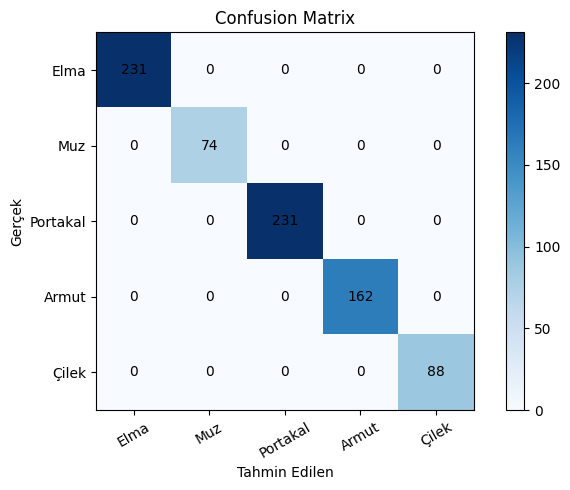

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# En iyi modeli yükle
model.load_state_dict(
    torch.load("best_fruit_cnn.pth", map_location=device)
)
model.eval()

all_labels = []
all_predictions = []
test_loss = 0

# Test verileri üzerinde tahmin
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        test_loss += loss.item() * images.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Performans metrikleri
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

test_loss = test_loss / len(test_dataset)

print("TEST SONUÇLARI")
print("--------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Accuracy:  {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-score:  {f1*100:.2f}%")

print("\nSINIF BAZLI SONUÇLAR")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(5)),
    target_names=class_names,
    zero_division=0
))

# Karışıklık matrisi
cm = confusion_matrix(
    all_labels, all_predictions, labels=list(range(5))
)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(5), class_names, rotation=30)
plt.yticks(range(5), class_names)
plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek")
plt.title("Confusion Matrix")

for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


In [18]:
import time

model.eval()

sample_image, _ = test_dataset[0]
sample_image = sample_image.unsqueeze(0).to(device)

# GPU ısınma
with torch.no_grad():
    for _ in range(10):
        model(sample_image)

if device.type == "cuda":
    torch.cuda.synchronize()

# 100 tahminin süresini ölç
start = time.perf_counter()

with torch.no_grad():
    for _ in range(100):
        model(sample_image)

if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

inference_time = (elapsed / 100) * 1000

print(f"Ortalama tahmin süresi: {inference_time:.3f} ms")


Ortalama tahmin süresi: 0.625 ms


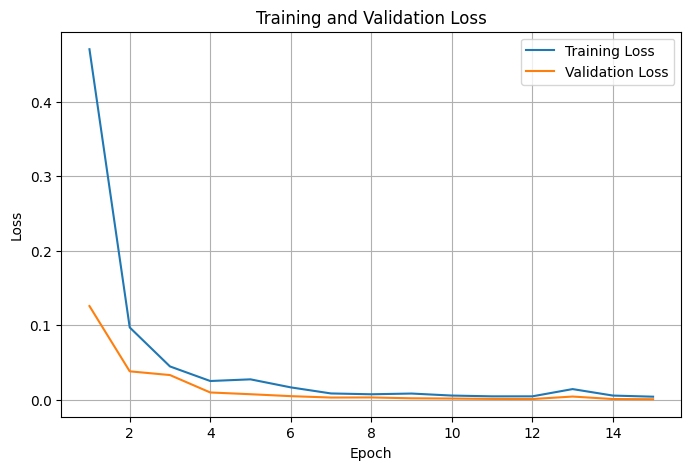

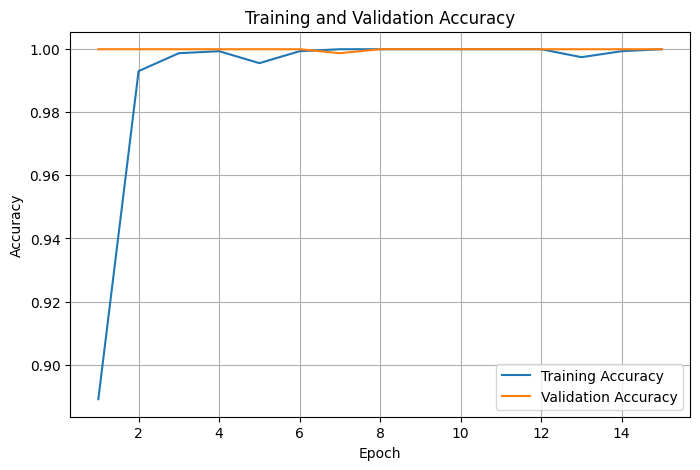

In [19]:
epochs_range = range(1, EPOCHS + 1)

# Loss grafiği
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], label="Training Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

# Accuracy grafiği
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_acc"], label="Training Accuracy")
plt.plot(epochs_range, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


In [20]:
import json

# Modeli kaydet
torch.save(model.state_dict(), "fruit_cnn_final.pth")

# Eğitim geçmişini kaydet
with open("training_history.json", "w") as f:
    json.dump(history, f)

# Sonuçları kaydet
results = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "training_time_seconds": training_time,
    "inference_time_ms": inference_time,
    "best_validation_accuracy": best_val_acc
}

with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model ve sonuçlar kaydedildi!")


Model ve sonuçlar kaydedildi!


In [21]:
!pip -q install gradio


In [22]:
import gradio as gr

def predict_fruit(image):
    if image is None:
        return "Lütfen bir fotoğraf yükleyin."

    image = image.convert("RGB")

    input_tensor = test_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()

    result = {
        class_names[i]: float(probabilities[i])
        for i in range(5)
    }

    return result


demo = gr.Interface(
    fn=predict_fruit,
    inputs=gr.Image(type="pil", label="Meyve fotoğrafı yükle"),
    outputs=gr.Label(num_top_classes=5, label="Model tahmini"),
    title="Fruit Classification Using CNN",
    description="Yapay zekâ modelimiz fotoğraftaki meyveyi tahmin eder."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://524ad0950f55685de7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [31]:
from google.colab import files
uploaded = files.upload()

Saving 572cf08d-6ef1-4354-8020-361e04815e0b.webp to 572cf08d-6ef1-4354-8020-361e04815e0b (3).webp
Saving 2dcd7e3e-89b0-4875-9a6a-787f948ed924.webp to 2dcd7e3e-89b0-4875-9a6a-787f948ed924 (3).webp
Saving 1000040120.jpg to 1000040120 (2).jpg
Saving 1000040121.jpg to 1000040121 (3).jpg
Saving image_aa84e9.jpg to image_aa84e9 (3).jpg


Fotoğraf: 572cf08d-6ef1-4354-8020-361e04815e0b (1).webp
Tahmin: Portakal
Güven: %41.93
------------------------------


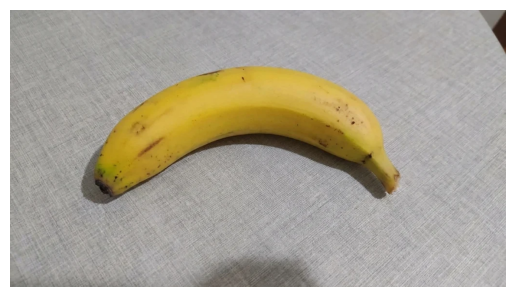

Fotoğraf: 2dcd7e3e-89b0-4875-9a6a-787f948ed924 (1).webp
Tahmin: Elma
Güven: %58.09
------------------------------


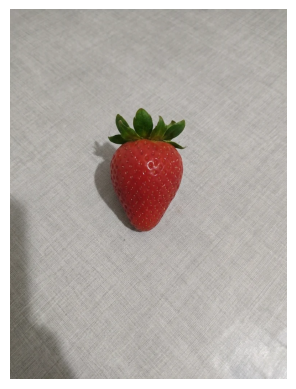

Fotoğraf: 1000040120 (1).jpg
Tahmin: Portakal
Güven: %66.59
------------------------------


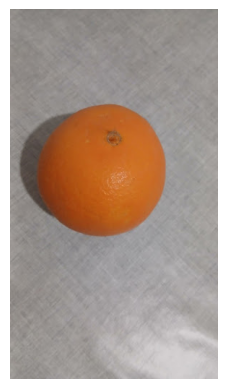

Fotoğraf: 1000040121 (2).jpg
Tahmin: Portakal
Güven: %59.16
------------------------------


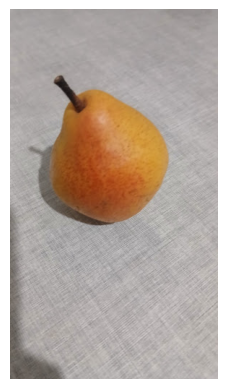

Fotoğraf: image_aa84e9 (2).jpg
Tahmin: Elma
Güven: %54.40
------------------------------


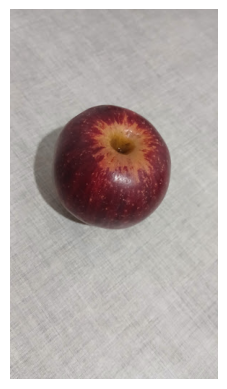

In [29]:
import matplotlib.pyplot as plt
from PIL import Image
import torch
import os

true_labels = {
    "elma": "Elma",
    "muz": "Muz",
    "portakal": "Portakal",
    "armut": "Armut",
    "cilek": "Çilek"
}

model.eval()

for filename in uploaded.keys():
    image = Image.open(filename).convert("RGB")
    input_tensor = test_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    prediction = class_names[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    print("Fotoğraf:", filename)
    print("Tahmin:", prediction)
    print(f"Güven: %{confidence:.2f}")
    print("-" * 30)

    plt.imshow(image)
    plt.axis("off")
    plt.show()